# Data Exploration

The purpose of this notebook is to understand what is in a recorded episode before doing any machine learning with it.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

EPISODES = Path("../data/raw/place_perturbed_400/episodes")

## One episode

Every episode is two files with the same name: an `.npz` with the arrays and a `.json` with everything else.

In [2]:
arrays = np.load(EPISODES / "episode_003.npz")
for key in arrays.files:
    print(f"{key:26s} {arrays[key].shape}  {arrays[key].dtype}")

observation.state          (316, 31)  float32
action                     (316, 31)  float32
timestamp                  (316,)  float64
info.phase                 (316,)  int16
privileged.object_pose     (316, 7)  float32


In [3]:
meta = json.loads((EPISODES / "episode_003.json").read_text())
print(list(meta.keys()))

['fps', 'frames', 'state_dim', 'state_names', 'slots', 'units', 'semantics', 'cameras', 'task', 'seed', 'episode', 'outcome', 'policy_info', 'randomisation', 'perturbation', 'quality', 'phases', 'privileged_keys', 'sim_model', 'controller', 'wall_s', 'policy', 'scenario', 'episode_index', 'generation']


`observation.state` and `action` have one row per frame and 31 columns. The JSON says what the columns are.

In [4]:
print(meta["slots"])
for i, name in enumerate(meta["state_names"]):
    print(i, name)

{'arm': [0, 14], 'hand': [14, 26], 'head': [26, 28], 'base': [28, 31]}
0 left_shoulder_pitch_joint
1 left_shoulder_roll_joint
2 left_shoulder_yaw_joint
3 left_elbow_joint
4 left_wrist_roll_joint
5 left_wrist_pitch_joint
6 left_wrist_yaw_joint
7 right_shoulder_pitch_joint
8 right_shoulder_roll_joint
9 right_shoulder_yaw_joint
10 right_elbow_joint
11 right_wrist_roll_joint
12 right_wrist_pitch_joint
13 right_wrist_yaw_joint
14 left_thumb_metacarpal_joint
15 left_thumb_proximal_joint
16 left_index_proximal_joint
17 left_middle_proximal_joint
18 left_ring_proximal_joint
19 left_pinky_proximal_joint
20 right_thumb_metacarpal_joint
21 right_thumb_proximal_joint
22 right_index_proximal_joint
23 right_middle_proximal_joint
24 right_ring_proximal_joint
25 right_pinky_proximal_joint
26 head_pan_joint
27 head_tilt_joint
28 base_vx
29 base_vy
30 base_wz


In [5]:
print(meta["task"])
print(meta["episode"]["arm"], meta["episode"]["object"], meta["episode"]["target"])
print(meta["outcome"])
print(meta["perturbation"])
print(meta["privileged_keys"])

place the blue can into the white tray
left blue_can white_tray
{'success': False, 'reason': 'blue_can is beside the white_tray', 'metrics': {'offset_x': 0.165, 'offset_y': -0.2468, 'height_m': -0.0122, 'released': 1.0, 'speed': 0.0}, 'first_success_s': None, 'frames': 316, 'seconds': 10.533, 'timed_out': False}
{'kind': 'drop', 'offset': [0.0126, -0.0554], 'at_s': 0.312, 'applied': True}
['privileged.object_pose', 'info.phase']


So in this episode the robot used the left arm, dropped the can and it ended up beside the tray.

`privileged.object_pose` and `info.phase` are marked as privileged: they only exist because this is a simulation. A real robot would not have them.

## What the hand does

Hand joints are columns 14 to 25: six for the left hand, then six for the right hand.

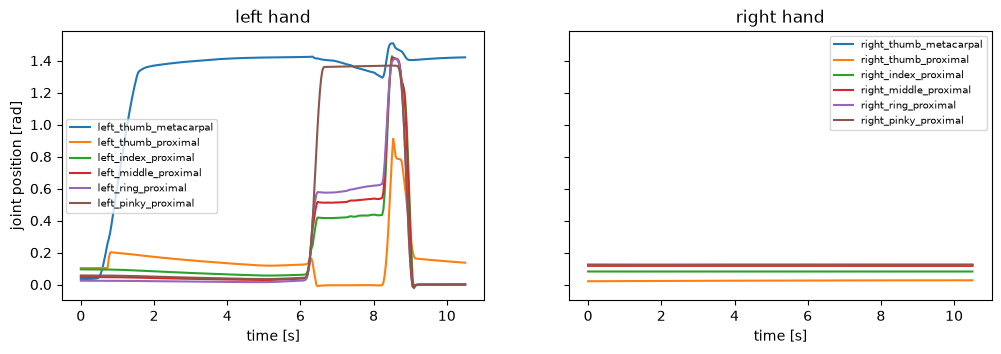

In [6]:
state = arrays["observation.state"]
t = arrays["timestamp"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for col in range(14, 20):
    axes[0].plot(t, state[:, col], label=meta["state_names"][col].replace("_joint", ""))
axes[0].set_title("left hand")
for col in range(20, 26):
    axes[1].plot(t, state[:, col], label=meta["state_names"][col].replace("_joint", ""))
axes[1].set_title("right hand")
for ax in axes:
    ax.set_xlabel("time [s]")
    ax.legend(fontsize=7)
axes[0].set_ylabel("joint position [rad]")
plt.show()

Only the left hand moves, the right hand stays where it started.

What I think is happening in the left hand:
- the thumb swings over early (`thumb_metacarpal` goes to 1.4 and stays there)
- at about 6.3 s the fingers close. Index, middle and ring stop at 0.4 to 0.6, probably because the can is in the way
- at about 8.3 s they suddenly go to 1.4. I think this is the moment the can is gone and nothing stops the fingers anymore
- then the hand opens and the episode ends

So the finger positions while the hand is closed could say something about whether the object is still in the hand.

## All episodes

Now the same for the whole dataset. The JSON files are enough for most of this.

In [7]:
metas = [json.loads(path.read_text()) for path in sorted(EPISODES.glob("*.json"))]
success = np.array([m["outcome"]["success"] for m in metas])

print("episodes:", len(metas))
print("successful:", success.sum(), "failed:", (~success).sum())
print("success rate:", round(success.mean(), 3))

episodes: 400
successful: 303 failed: 97
success rate: 0.758


About three out of four episodes succeed. That means a model that always says "success" is already right 76 % of the time, so accuracy alone is not a good score here.

In [8]:
for key in ["arm", "object", "target"]:
    print(key)
    for value in sorted({m["episode"][key] for m in metas}):
        chosen = np.array([m["episode"][key] == value for m in metas])
        print(f"  {value:12s} n={chosen.sum():3d}  success rate={success[chosen].mean():.2f}")

print("perturbation")
for value in sorted({m["perturbation"]["kind"] for m in metas}):
    chosen = np.array([m["perturbation"]["kind"] == value for m in metas])
    print(f"  {value:12s} n={chosen.sum():3d}  success rate={success[chosen].mean():.2f}")

arm
  left         n=192  success rate=0.74
  right        n=208  success rate=0.77
object
  blue_can     n= 89  success rate=0.65
  green_cube   n= 92  success rate=0.78
  red_cube     n=104  success rate=0.84
  yellow_ball  n=115  success rate=0.75
target
  purple_tray  n=192  success rate=0.76
  white_tray   n=208  success rate=0.76
perturbation
  drop         n=124  success rate=0.42
  nudge        n=176  success rate=0.92
  slip         n=100  success rate=0.89


In [9]:
reasons = [m["outcome"]["reason"] for m in metas if not m["outcome"]["success"]]
print({reason.split(" is ")[1] for reason in reasons})

{'beside the purple_tray', 'beside the white_tray'}


Every episode has one disturbance. A "drop" is by far the most harmful one, the robot recovers from most slips and nudges.

All failures are the same kind: the object ends up beside the tray. Left and right arm fail about equally often.

## How long do episodes take?

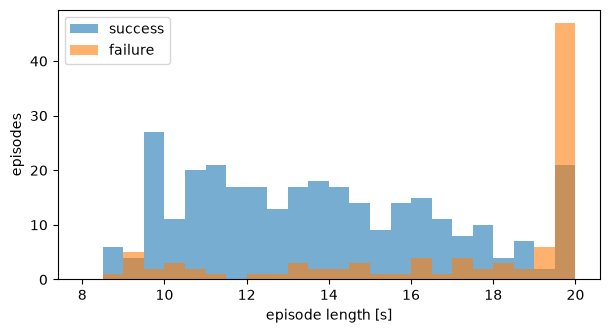

timed out and failed: 41
timed out and successful: 18


In [10]:
seconds = np.array([m["outcome"]["seconds"] for m in metas])
timed_out = np.array([m["outcome"]["timed_out"] for m in metas])

plt.figure(figsize=(7, 3.5))
bins = np.linspace(8, 20, 25)
plt.hist(seconds[success], bins=bins, alpha=0.6, label="success")
plt.hist(seconds[~success], bins=bins, alpha=0.6, label="failure")
plt.xlabel("episode length [s]")
plt.ylabel("episodes")
plt.legend()
plt.show()

print("timed out and failed:", (timed_out & ~success).sum())
print("timed out and successful:", (timed_out & success).sum())

Episodes are cut off at 20 s. Almost half of the failures (41 of 97) run into that limit, but 18 successful episodes do too, so "it timed out" is a hint and not the answer. Successful episodes are spread between 9 and 19 s.

## A successful and a failed episode side by side

Both episodes use the left arm, so the same columns can be compared.

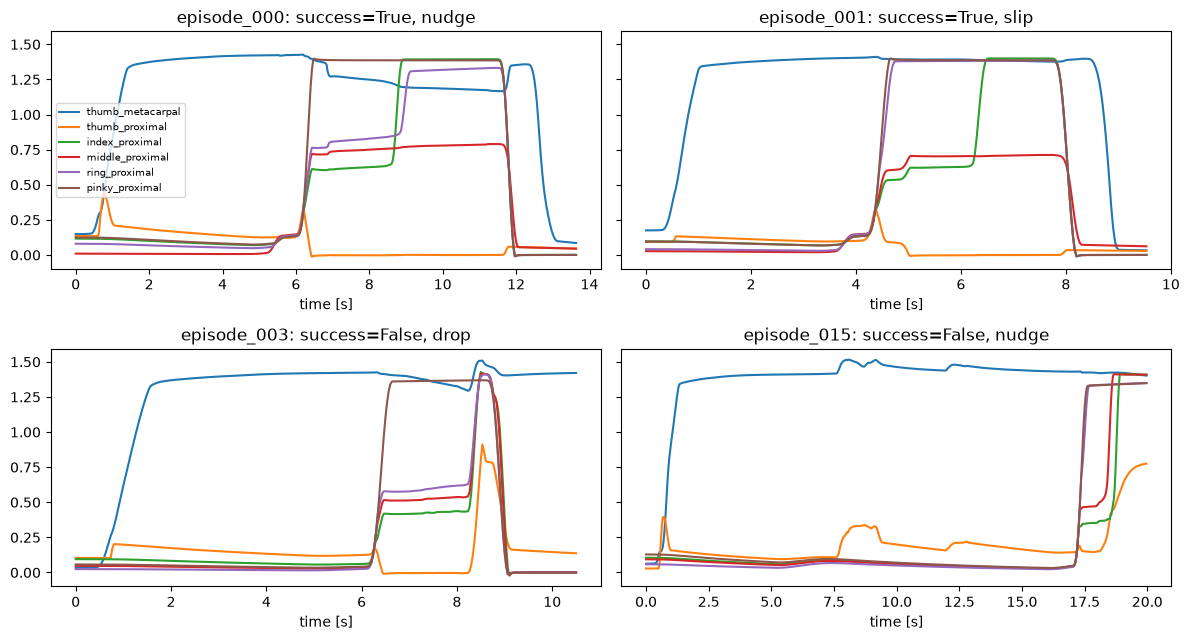

In [11]:
def plot_left_hand(ax, name):
    arrays = np.load(EPISODES / f"{name}.npz")
    meta = json.loads((EPISODES / f"{name}.json").read_text())
    for col in range(14, 20):
        label = meta["state_names"][col].replace("left_", "").replace("_joint", "")
        ax.plot(arrays["timestamp"], arrays["observation.state"][:, col], label=label)
    ax.set_title(f"{name}: success={meta['outcome']['success']}, {meta['perturbation']['kind']}")
    ax.set_xlabel("time [s]")


left_ok = [m for m in metas if m["episode"]["arm"] == "left" and m["outcome"]["success"]]
left_failed = [m for m in metas if m["episode"]["arm"] == "left" and not m["outcome"]["success"]]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharey=True)
for ax, m in zip(axes[0], left_ok[:2]):
    plot_left_hand(ax, f"episode_{m['episode_index']:03d}")
for ax, m in zip(axes[1], left_failed[:2]):
    plot_left_hand(ax, f"episode_{m['episode_index']:03d}")
axes[0][0].legend(fontsize=7)
plt.tight_layout()
plt.show()

My idea from above (fingers at 1.4 means the object is gone) is too simple: in the successful episodes some fingers also go to 1.4 while the object is held.

What does look different is the end of the episode. Both successful episodes end with the hand open and the thumb back near 0. In episode_003 the thumb stays at 1.4, and episode_015 is still closing the hand when the time runs out. These are only four episodes, so this is something to test and not a result.

## Are the files consistent?

In [12]:
problems = 0
for path in sorted(EPISODES.glob("*.npz")):
    arrays = np.load(path)
    frames = len(arrays["timestamp"])
    if arrays["observation.state"].shape != (frames, 31) or arrays["action"].shape != (frames, 31):
        problems += 1
    if np.isnan(arrays["observation.state"]).any() or np.isnan(arrays["action"]).any():
        problems += 1
print("files with problems:", problems)

frames = np.array([m["frames"] for m in metas])
print("frames per episode: min", frames.min(), "max", frames.max())

files with problems: 0
frames per episode: min 257 max 600


## Conclusions

- An episode is `observation.state`, `action` (both frames x 31) and `timestamp`, plus a JSON with the outcome. No missing values, between 257 and 600 frames.
- The label is `outcome.success` from the JSON: 303 successful, 97 failed. Because of the imbalance I will look at the F1 score per class and not only at accuracy.
- `privileged.object_pose` and `info.phase` must not be used as model input. A real robot does not have them, and the outcome is computed from the object pose, so using it would just give the answer away.
- Only one arm is used per episode (`episode.arm` in the JSON). Features should be built from the active arm, otherwise a left-arm and a right-arm episode look completely different to the model.
- Things that might separate success from failure: episode length, and what the hand looks like at the end.